# Hostel Mess Food Wastage Analysis – Data Analyst Project
**Audience:** B.Tech 1st Year students (Data Analyst track) | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
The hostel administration wants to understand **what drives daily food wastage (`Food_Wasted_Kg`)** across hostel blocks and meal sessions so that mess managers can optimize preparation quantities and reduce waste.

**Questions we will answer**
1. What does `Food_Wasted_Kg` look like overall (typical value, spread, shape)?
2. Do `Food_Prepared_Kg` and `Students_Present` affect `Food_Wasted_Kg`?
3. Does `Food_Wasted_Kg` differ by `Hostel_Block`, `Meal_Type`, `Day_Type` and `Menu_Category`?
4. Which records need attention? Define **"High Waste"** as wastage above a chosen, justified threshold (e.g., > 30 kg / ~90th percentile) and describe what those records have in common.

> The dataset is **synthetic** (computer-generated) and contains no real hostel operations data.

## 2. Import libraries

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

## 3. Load and inspect the data

In [20]:
df = pd.read_csv('../data/raw/hostel_mess_data.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (255, 12)


,Record_ID,Hostel_Block,Meal_Type,Day_Type,Menu_Category,Food_Prepared_Kg,Students_Present,Menu_Rating,Serving_Duration_Min,Outside_Temp_C,Record_Date,Food_Wasted_Kg
0,M1153,Aryabhatta,Lunch,Weekend,Regular,83.2,240,3.4,45.0,27.3,2025-04-05,11.7
1,M1073,Aryabhatta,Breakfast,Weekday,Regular,92.2,326,1.7,52.0,32.3,2026-01-23,1.0
2,M1176,Bhaskara,Breakfast,Weekday,Festival Feast,129.9,275,3.2,62.0,35.0,2025-08-16,18.1
3,M1125,Ramanujan,Breakfast,Weekend,Regular,177.9,223,4.2,93.0,28.0,2025-02-05,40.8
4,M1068,Bhaskara,Lunch,Weekday,Regular,100.3,230,3.2,44.0,37.5,2024-12-22,21.7


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Record_ID             255 non-null    str    
 1   Hostel_Block          255 non-null    str    
 2   Meal_Type             249 non-null    str    
 3   Day_Type              255 non-null    str    
 4   Menu_Category         255 non-null    str    
 5   Food_Prepared_Kg      249 non-null    float64
 6   Students_Present      255 non-null    int64  
 7   Menu_Rating           251 non-null    float64
 8   Serving_Duration_Min  251 non-null    float64
 9   Outside_Temp_C        255 non-null    float64
 10  Record_Date           255 non-null    str    
 11  Food_Wasted_Kg        255 non-null    float64
dtypes: float64(5), int64(1), str(6)
memory usage: 24.0 KB


In [22]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)

Missing values per column:
Meal_Type               6
Food_Prepared_Kg        6
Menu_Rating             4
Serving_Duration_Min    4
dtype: int64

Duplicate rows: 5


,Food_Prepared_Kg,Students_Present,Menu_Rating,Serving_Duration_Min,Outside_Temp_C,Food_Wasted_Kg
count,249.0,255.0,251.0,251.0,255.0,255.0
mean,119.3,225.4,3.5,54.3,30.4,20.0
std,29.5,63.2,0.6,12.5,5.7,9.9
min,50.0,-120.0,1.7,28.0,15.2,1.0
25%,98.0,186.0,3.1,46.0,27.0,12.9
50%,120.1,227.0,3.4,53.0,30.5,20.6
75%,138.9,265.0,3.9,63.0,34.0,26.9
max,186.5,390.0,5.0,93.0,45.0,55.5


**What we found:** 5 duplicate rows, missing values (`Meal_Type`, `Food_Prepared_Kg`, `Menu_Rating`, `Serving_Duration_Min`), inconsistent whitespace/capitalization in `Hostel_Block` (e.g. `ARYABHATTA`, `Ramanujan  `, ` Kalpana`), and impossible negative values in `Students_Present` (`-120`, `-45`). We clean these next.

## 4. Clean the data

In [23]:
clean = df.copy()

# 1. Remove duplicate rows
clean = clean.drop_duplicates().copy()

# 2. Standardise text columns
for col in ['Hostel_Block', 'Meal_Type', 'Day_Type', 'Menu_Category']:
    clean[col] = clean[col].str.strip().str.title()

# 3. Fix impossible values (Students_Present must be > 0)
clean.loc[clean['Students_Present'] <= 0, 'Students_Present'] = np.nan

# 4. Fill missing categorical with mode & numeric with median (robust to outliers)
clean['Meal_Type'] = clean['Meal_Type'].fillna(clean['Meal_Type'].mode()[0])
num_cols = ['Food_Prepared_Kg', 'Students_Present', 'Menu_Rating', 'Serving_Duration_Min', 'Outside_Temp_C', 'Food_Wasted_Kg']
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].median())
clean['Students_Present'] = clean['Students_Present'].astype(int)

print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

Rows after cleaning: 250 | Missing values left: 0


## 5. Create new columns (feature engineering)

In [24]:
# Percentage of prepared food wasted
clean['Waste_Pct'] = ((clean['Food_Wasted_Kg'] / clean['Food_Prepared_Kg']) * 100).round(1)

# Food prepared and wasted per student (Kg)
clean['Food_Per_Student_Kg'] = (clean['Food_Prepared_Kg'] / clean['Students_Present']).round(3)
clean['Waste_Per_Student_Kg'] = (clean['Food_Wasted_Kg'] / clean['Students_Present']).round(3)

# Define High Waste threshold (> 30.0 Kg, which aligns with the ~90th percentile)
p90_threshold = clean['Food_Wasted_Kg'].quantile(0.90)
HIGH_WASTE_LIMIT = 30.0
print(f'90th Percentile: {p90_threshold:.2f} Kg | Chosen High Waste Threshold: > {HIGH_WASTE_LIMIT} Kg')

def waste_band(w):
    if w > HIGH_WASTE_LIMIT:
        return 'High Waste'
    elif w >= 15.0:
        return 'Moderate Waste'
    return 'Low Waste'

clean['Waste_Category'] = clean['Food_Wasted_Kg'].apply(waste_band)
clean['Attendance_Band'] = pd.cut(clean['Students_Present'], [0, 180, 230, 280, 500], labels=['<180', '180-230', '230-280', '>280'])

clean[['Record_ID', 'Food_Prepared_Kg', 'Students_Present', 'Food_Wasted_Kg', 'Waste_Pct', 'Waste_Category']].head()

90th Percentile: 32.32 Kg | Chosen High Waste Threshold: > 30.0 Kg


,Record_ID,Food_Prepared_Kg,Students_Present,Food_Wasted_Kg,Waste_Pct,Waste_Category
0,M1153,83.2,240,11.7,14.1,Low Waste
1,M1073,92.2,326,1.0,1.1,Low Waste
2,M1176,129.9,275,18.1,13.9,Moderate Waste
3,M1125,177.9,223,40.8,22.9,High Waste
4,M1068,100.3,230,21.7,21.6,Moderate Waste


## 6. Exploratory data analysis (EDA)

### Q1. What does Food_Wasted_Kg look like overall (typical value, spread, shape)?

count    250.00
mean      19.95
std        9.98
min        1.00
25%       12.82
50%       20.55
75%       26.78
max       55.50
Name: Food_Wasted_Kg, dtype: float64
IQR: 13.96 Kg | Skewness: 0.17


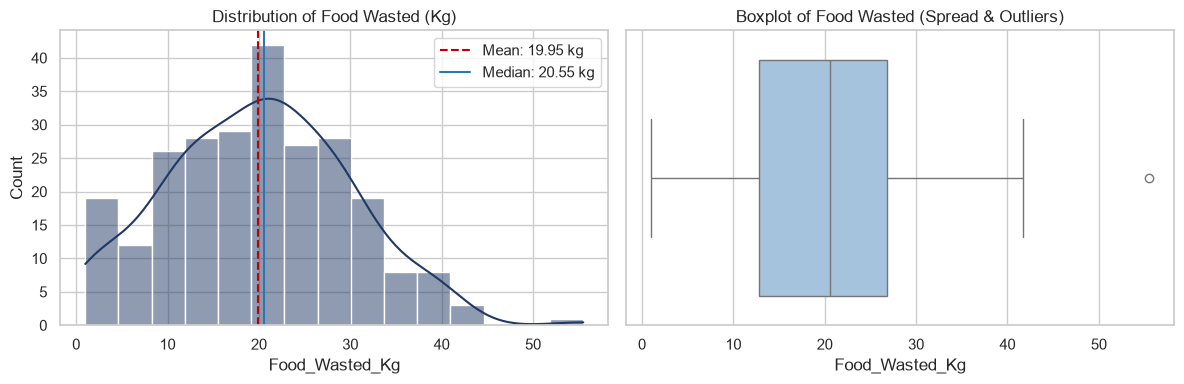

In [25]:
stats = clean['Food_Wasted_Kg'].describe().round(2)
iqr = stats['75%'] - stats['25%']
skew = clean['Food_Wasted_Kg'].skew()
print(stats)
print(f'IQR: {iqr:.2f} Kg | Skewness: {skew:.2f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean['Food_Wasted_Kg'], bins=15, kde=True, color='#1F3864', ax=ax[0])
ax[0].axvline(stats['mean'], color='#C00000', linestyle='--', label=f"Mean: {stats['mean']} kg")
ax[0].axvline(stats['50%'], color='#2E75B6', linestyle='-', label=f"Median: {stats['50%']} kg")
ax[0].set_title('Distribution of Food Wasted (Kg)')
ax[0].legend()

sns.boxplot(x=clean['Food_Wasted_Kg'], color='#9DC3E6', ax=ax[1])
ax[1].set_title('Boxplot of Food Wasted (Spread & Outliers)')
plt.tight_layout()
plt.show()

### Q2. Do Food_Prepared_Kg and Students_Present affect Food_Wasted_Kg?

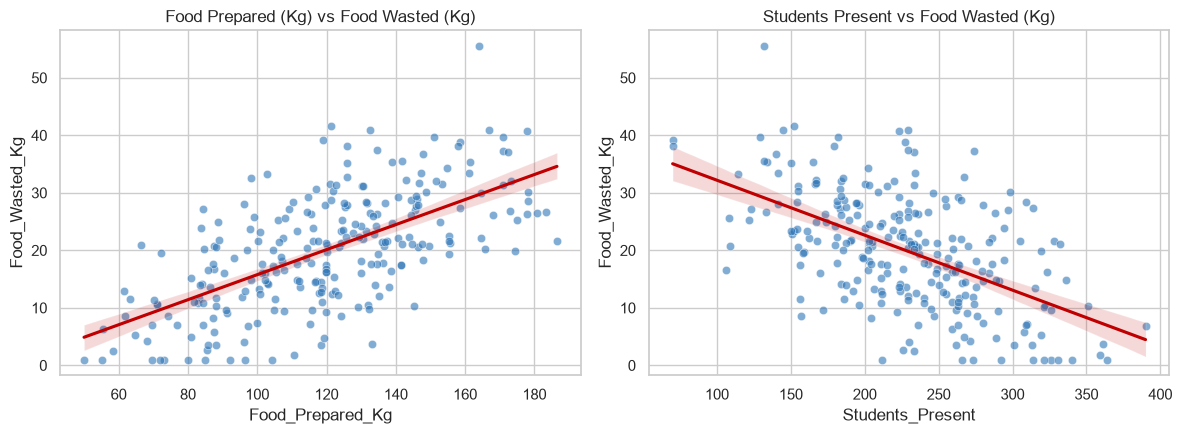

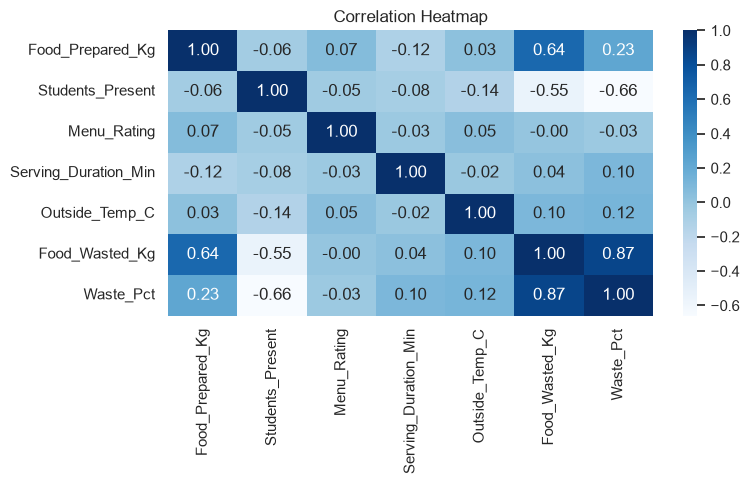

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=clean, x='Food_Prepared_Kg', y='Food_Wasted_Kg', alpha=0.6, color='#2E75B6', ax=ax[0])
sns.regplot(data=clean, x='Food_Prepared_Kg', y='Food_Wasted_Kg', scatter=False, color='#C00000', ax=ax[0])
ax[0].set_title('Food Prepared (Kg) vs Food Wasted (Kg)')

sns.scatterplot(data=clean, x='Students_Present', y='Food_Wasted_Kg', alpha=0.6, color='#2E75B6', ax=ax[1])
sns.regplot(data=clean, x='Students_Present', y='Food_Wasted_Kg', scatter=False, color='#C00000', ax=ax[1])
ax[1].set_title('Students Present vs Food Wasted (Kg)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
corr_cols = ['Food_Prepared_Kg', 'Students_Present', 'Menu_Rating', 'Serving_Duration_Min', 'Outside_Temp_C', 'Food_Wasted_Kg', 'Waste_Pct']
sns.heatmap(clean[corr_cols].corr().round(2), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### Q3. Does Food_Wasted_Kg differ by Hostel_Block, Meal_Type, Day_Type and Menu_Category?

--- Food Wasted (Kg) by Hostel_Block ---
              count   mean  median
Hostel_Block                      
Aryabhatta       80  19.70   20.60
Bhaskara         72  18.32   18.55
Kalpana          61  20.77   21.10
Ramanujan        37  22.28   22.20 

--- Food Wasted (Kg) by Meal_Type ---
           count   mean  median
Meal_Type                      
Breakfast     62  21.27   20.55
Dinner       103  18.96   20.70
Lunch         85  20.18   20.20 

--- Food Wasted (Kg) by Day_Type ---
          count   mean  median
Day_Type                      
Holiday      17  26.26   23.90
Weekday     168  17.96   17.75
Weekend      65  23.43   23.90 

--- Food Wasted (Kg) by Menu_Category ---
                count   mean  median
Menu_Category                       
Festival Feast     23  19.52    19.7
Regular           162  19.66    20.0
Special            65  20.81    21.6 



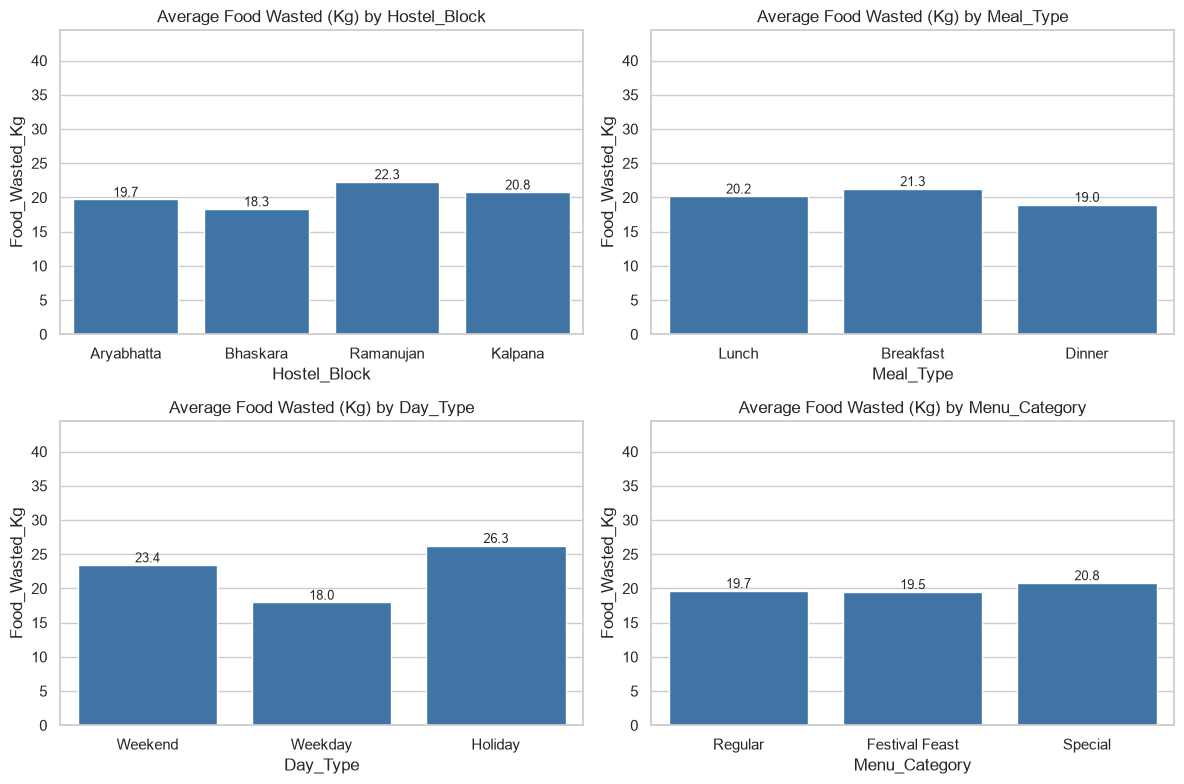

In [27]:
group_cols = ['Hostel_Block', 'Meal_Type', 'Day_Type', 'Menu_Category']
for col in group_cols:
    print(f'--- Food Wasted (Kg) by {col} ---')
    print(clean.groupby(col)['Food_Wasted_Kg'].agg(['count', 'mean', 'median']).round(2), '\n')

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, col in zip(ax.flat, group_cols):
    sns.barplot(data=clean, x=col, y='Food_Wasted_Kg', errorbar=None, color='#2E75B6', ax=a)
    a.set_title(f'Average Food Wasted (Kg) by {col}')
    a.set_ylim(0, clean['Food_Wasted_Kg'].max() * 0.8)
    for p in a.patches:
        a.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

### Q4. Which records need attention? (High Waste > 30 Kg)

In [28]:
high_waste = clean[clean['Food_Wasted_Kg'] > HIGH_WASTE_LIMIT].sort_values('Food_Wasted_Kg', ascending=False)
normal_waste = clean[clean['Food_Wasted_Kg'] <= HIGH_WASTE_LIMIT]

print(f'{len(high_waste)} records ({len(high_waste)/len(clean):.1%}) exceed {HIGH_WASTE_LIMIT} Kg (High Waste)')
print('\nComparison: High Waste vs Normal Records (Means):')
comp = pd.DataFrame({
    'High Waste (>30kg)': high_waste[['Food_Prepared_Kg', 'Students_Present', 'Menu_Rating', 'Serving_Duration_Min', 'Waste_Pct', 'Food_Per_Student_Kg']].mean().round(2),
    'Normal (<=30kg)': normal_waste[['Food_Prepared_Kg', 'Students_Present', 'Menu_Rating', 'Serving_Duration_Min', 'Waste_Pct', 'Food_Per_Student_Kg']].mean().round(2)
})
print(comp)

print('\nTop 10 High Waste Records:')
high_waste[['Record_ID', 'Hostel_Block', 'Meal_Type', 'Day_Type', 'Menu_Category', 'Food_Prepared_Kg', 'Students_Present', 'Food_Wasted_Kg', 'Waste_Pct']].head(10)

39 records (15.6%) exceed 30.0 Kg (High Waste)

Comparison: High Waste vs Normal Records (Means):
                      High Waste (>30kg)  Normal (<=30kg)
Food_Prepared_Kg                  144.56           114.52
Students_Present                  181.87           236.61
Menu_Rating                         3.47             3.49
Serving_Duration_Min               56.95            53.62
Waste_Pct                          24.92            14.75
Food_Per_Student_Kg                 0.86             0.51

Top 10 High Waste Records:


,Record_ID,Hostel_Block,Meal_Type,Day_Type,Menu_Category,Food_Prepared_Kg,Students_Present,Food_Wasted_Kg,Waste_Pct
61,M1239,Kalpana,Breakfast,Weekend,Regular,164.1,132,55.5,33.8
218,M1175,Aryabhatta,Dinner,Holiday,Special,121.2,152,41.7,34.4
254,M1139,Bhaskara,Lunch,Weekend,Regular,166.8,229,41.0,24.6
180,M1185,Aryabhatta,Breakfast,Holiday,Festival Feast,132.6,145,41.0,30.9
3,M1125,Ramanujan,Breakfast,Weekend,Regular,177.9,223,40.8,22.9
73,M1098,Aryabhatta,Dinner,Weekday,Regular,151.0,129,39.7,26.3
202,M1234,Kalpana,Lunch,Weekday,Regular,170.8,182,39.7,23.2
55,M1047,Kalpana,Lunch,Weekday,Regular,119.0,70,39.1,32.9
48,M1055,Ramanujan,Lunch,Holiday,Regular,158.6,227,38.8,24.5
117,M1198,Bhaskara,Lunch,Weekend,Special,157.8,179,38.2,24.2


## 7. Key insights (generated from the data)

In [29]:
r_prep = clean['Food_Prepared_Kg'].corr(clean['Food_Wasted_Kg'])
r_stud = clean['Students_Present'].corr(clean['Food_Wasted_Kg'])
worst_block = clean.groupby('Hostel_Block')['Food_Wasted_Kg'].mean().idxmax()
best_block = clean.groupby('Hostel_Block')['Food_Wasted_Kg'].mean().idxmin()
worst_meal = clean.groupby('Meal_Type')['Food_Wasted_Kg'].mean().idxmax()

print(f"1. Overall wastage: mean = {clean['Food_Wasted_Kg'].mean():.1f} kg; median = {clean['Food_Wasted_Kg'].median():.1f} kg; std = {clean['Food_Wasted_Kg'].std():.1f} kg.")
print(f"2. Food_Prepared_Kg vs Waste r = {r_prep:.2f}; Students_Present vs Waste r = {r_stud:.2f}.")
print(f"3. Highest average waste block: {worst_block}; lowest: {best_block}; highest-waste meal: {worst_meal}.")
print(f"4. {len(high_waste)} records ({len(high_waste)/len(clean):.1%}) are High Waste (> {HIGH_WASTE_LIMIT} kg), driven by over-preparation relative to attendance.")

1. Overall wastage: mean = 19.9 kg; median = 20.6 kg; std = 10.0 kg.
2. Food_Prepared_Kg vs Waste r = 0.64; Students_Present vs Waste r = -0.55.
3. Highest average waste block: Ramanujan; lowest: Bhaskara; highest-waste meal: Breakfast.
4. 39 records (15.6%) are High Waste (> 30.0 kg), driven by over-preparation relative to attendance.


## 8. Recommendations & Save Processed CSV
- **Cap batch cooking buffers** when `Food_Per_Student_Kg` exceeds ~0.60 kg/student.
- **Pre-meal headcount check-ins** (especially on weekends/holidays and Festival Feasts) to align `Food_Prepared_Kg` with actual `Students_Present`.
- **Audit high-waste meal slots** identified in Section 6 (Q4).

In [30]:
clean.to_csv('hostel_mess_data_clean.csv', index=False)
print('Saved cleaned & processed dataset with', len(clean), 'rows and', clean.shape[1], 'columns.')

Saved cleaned & processed dataset with 250 rows and 17 columns.
